Guilherme Aguilar
Ian Moraes

In [10]:
import numpy as np

In [13]:
def criar_funcao_oculta(s, num_bits):
    inputs = [x for x in range(2**num_bits)]
    inputs2 = [x for x in range(2**num_bits)]
    np.random.shuffle(inputs)
    np.random.shuffle(inputs2)
    mappings = {}
    for i in range(2**(num_bits-1)):
        mappings[i] = inputs2[i]
        mappings[i ^ s] = inputs2[i]
    return mappings

f(0) = 7
f(1) = 3
f(2) = 4
f(3) = 2
f(4) = 4
f(5) = 2
f(6) = 7
f(7) = 3


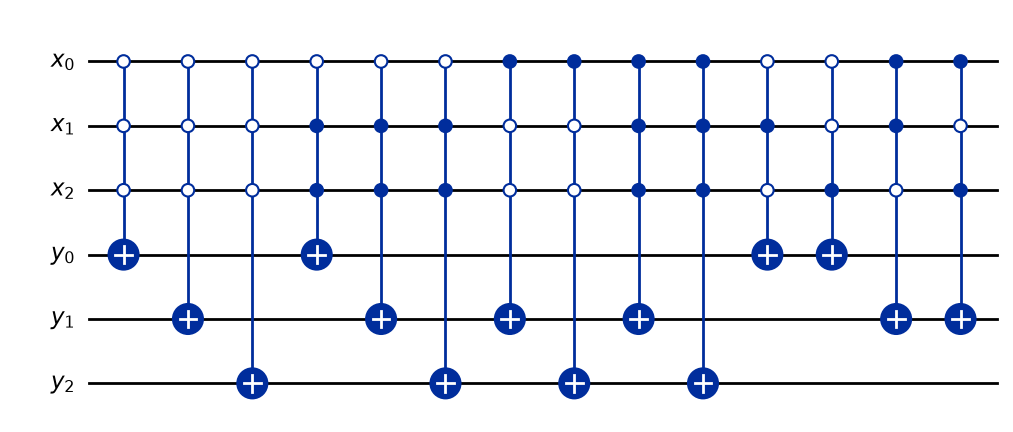

In [26]:
from qiskit.circuit.library import MCXGate
s = 0b110
f_dict = criar_funcao_oculta(s, 3)


for i in range(2**3):
    print(f'f({i}) =', f_dict[i])

qr_in = QuantumRegister(3, name='x')
qr_out = QuantumRegister(3, name='y')
qc = QuantumCircuit(qr_in, qr_out, name='U_f')

for x, f_x in f_dict.items():
    x_bin = format(x, '03b')
    f_bin = format(f_x, '03b')
    
    for i, bit in enumerate(f_bin):
        if bit == '1':
            ctrl_state = int(x_bin, 2)

            qc.append(MCXGate(3, ctrl_state=ctrl_state), 
                      qr_in[:] + [qr_out[i]])

display(qc.draw('mpl'))
oraculo_gate = qc.to_gate()

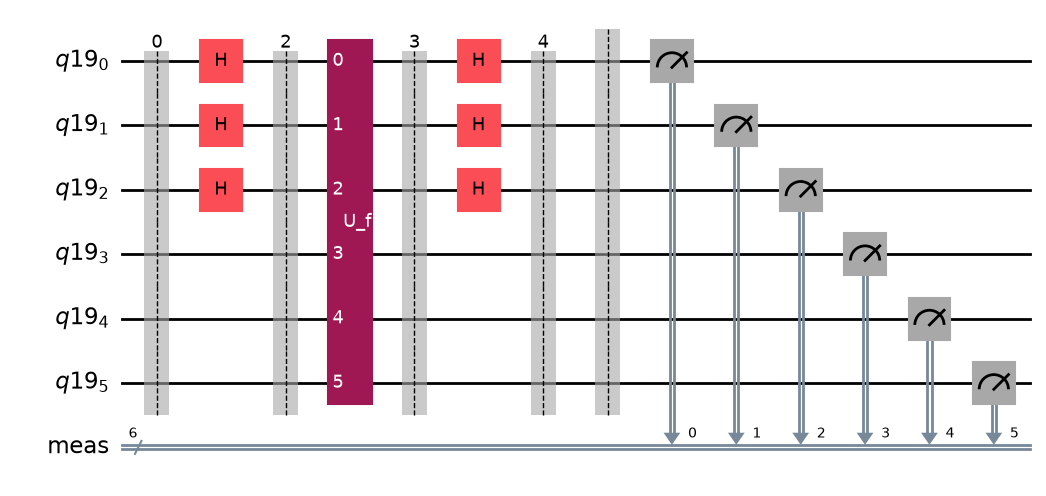

In [39]:
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Statevector
import math

qr = QuantumRegister(6)
qc = QuantumCircuit(qr)
qc.barrier(label='0')
qc.h(0)
qc.h(1)
qc.h(2)
qc.barrier(label='2')
qc.append(oraculo_gate, [0, 1, 2, 3, 4, 5])
qc.barrier(label='3')
qc.h(0)
qc.h(1)
qc.h(2)
qc.barrier(label='4')
qc.measure_all()


#sv = Statevector(qc)
qc.draw('mpl')

In [68]:
sampler = StatevectorSampler()
ws = []
result = sampler.run([qc], shots=1).result()
print(list(result[0].data.meas.get_counts().keys())[0])
list(result[0].data.meas.get_counts().keys())[0][3:]

010111


'111'

In [77]:
sampler = StatevectorSampler()
ws = []
iter = 0
while len(ws) < 2:
    result = sampler.run([qc], shots=1).result()
    candidato_raw = list(result[0].data.meas.get_counts().keys())[0][0:3]
    print(candidato_raw)
    candidato = int(candidato_raw, base = 2)
    if candidato == 0:
        iter += 1
        continue

    if candidato not in ws:
        ws.append(candidato)

    iter += 1
print('num_iter =', iter)
print(ws)

001
001
110
num_iter = 3
[1, 6]


In [ ]:
bits_mask = [1, 2, 4]
for w in ws:
    equacao = []
    for i, bit in enumerate(bits_mask):
        if w & bit > 0:
            equacao.append(f's{i+1}')
    print(' +'.join(equacao) + ' = 0')

s1 = 0
 = 0
